<a href="https://colab.research.google.com/github/Lathika-M732/24ADI006_DL-EX-7/blob/main/EX_7_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IMPLEMENTATION OF A SIMPLE AUTOENCODER FOR DIMENSIONALITY REDUCTION AND FEATURE LEARNING**

# Name : Lathika M
# Roll No : 24BAD062

# PART A: DATASET PREPARATION

EXPT NO: 7
Name: Lathika M
Roll No: 24BAD062
Experiment: Autoencoder for Dimensionality Reduction
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Dataset Information
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
Data Type: uint8
After Reshaping:
Training Shape: (60000, 784)
Testing Shape: (10000, 784)


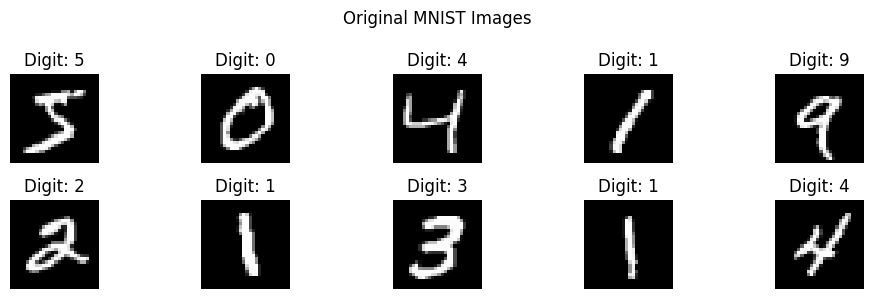

In [ ]:
# PART A: DATASET PREPARATION

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

# Student Details
print("EXPT NO: 7")
print("Name: Lathika M")
print("Roll No: 24BAD062")
print("Experiment: Autoencoder for Dimensionality Reduction")

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Display dataset information
print("\nDataset Information")
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)
print("Data Type:", x_train.dtype)

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape images into 1D vectors
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("After Reshaping:")
print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

# Display sample original images
plt.figure(figsize=(10, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title(f"Digit: {y_train[i]}")
    plt.axis('off')

plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()

# PART B: IMPLEMENTING THE AUTOENCODER MODEL

In [ ]:
# PART B: IMPLEMENTING THE AUTOENCODER MODEL

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# Student Details
print("Name: Lathika M")
print("Roll No: 24BAD062")

# Define input dimension
input_dim = 784
encoding_dim = 32

# Encoder
input_layer = Input(shape=(input_dim,))

encoded = Dense(128, activation='relu')(input_layer)
encoded = Dense(64, activation='relu')(encoded)

# Bottleneck Layer
bottleneck = Dense(encoding_dim, activation='relu',
                   name='Bottleneck')(encoded)

# Decoder
decoded = Dense(64, activation='relu')(bottleneck)
decoded = Dense(128, activation='relu')(decoded)

output_layer = Dense(784, activation='sigmoid')(decoded)

# Create Autoencoder
autoencoder = Model(input_layer, output_layer)

# Create Encoder separately
encoder = Model(input_layer, bottleneck)

# Create Decoder separately
decoder_input = Input(shape=(encoding_dim,))
decoder_layer1 = autoencoder.layers[-3](decoder_input)
decoder_layer2 = autoencoder.layers[-2](decoder_layer1)
decoder_output = autoencoder.layers[-1](decoder_layer2)

decoder = Model(decoder_input, decoder_output)

# Compile model
autoencoder.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# Display model summary
print("\nAUTOENCODER MODEL SUMMARY")
autoencoder.summary()

print("\nENCODER MODEL SUMMARY")
encoder.summary()

print("\nDECODER MODEL SUMMARY")
decoder.summary()

print("\nAutoencoder Model Created Successfully!")

Name: Lathika M
Roll No: 24BAD062

AUTOENCODER MODEL SUMMARY


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Bottleneck (Dense)              │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 111,568 (435.81 KB)

 Trainable params: 111,568 (435.81 KB)

 Non-trainable params: 0 (0.00 B)


Autoencoder Model Created Successfully!


# PART C: MODEL TRAINING AND PERFORMANCE EVALUATION

Name: Lathika M
Roll No: 24BAD062
Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 0.0629 - val_loss: 0.0371
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0305 - val_loss: 0.0250
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0232 - val_loss: 0.0209
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0203 - val_loss: 0.0192
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0186 - val_loss: 0.0175
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0171 - val_loss: 0.0159
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0156 - val_loss: 0.0145
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0145 - val_loss: 0.0137
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0137 - val_loss: 0.0130
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 0.0131 - val_loss: 0.0125
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0125

MODEL PERFORMANCE
Training Loss: 0.013

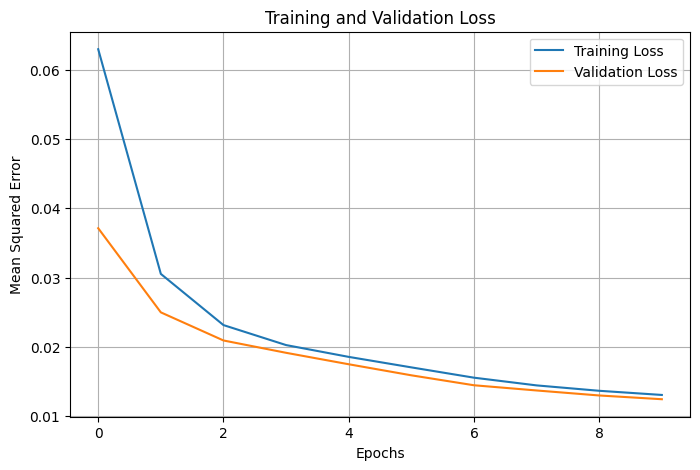

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


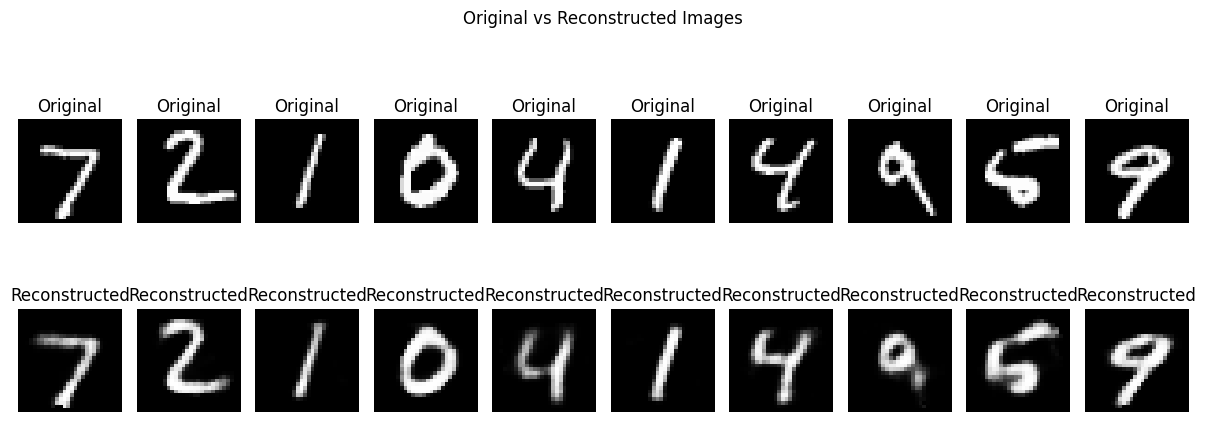

In [ ]:
# PART C: MODEL TRAINING AND PERFORMANCE EVALUATION

# Student Details
print("Name: Lathika M")
print("Roll No: 24BAD062")

# Train the Autoencoder
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

# Evaluate the model
test_loss = autoencoder.evaluate(x_test, x_test)

print("\nMODEL PERFORMANCE")
print("Training Loss:", history.history['loss'][-1])
print("Validation Loss:", history.history['val_loss'][-1])
print("Test Reconstruction MSE:", test_loss)

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid()
plt.show()

# Reconstruct test images
reconstructed = autoencoder.predict(x_test[:10])

# Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):
    # Original images
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed images
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.suptitle("Original vs Reconstructed Images")
plt.tight_layout()
plt.show()


PART D: DIMENSIONALITY REDUCTION, FEATURE VISUALIZATION AND EXPERIMENT MANAGEMENT


Name: Lathika M
Roll No: 24BAD062
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

DIMENSIONALITY REDUCTION
Original Data Shape: (10000, 784)
Compressed Data Shape: (10000, 32)


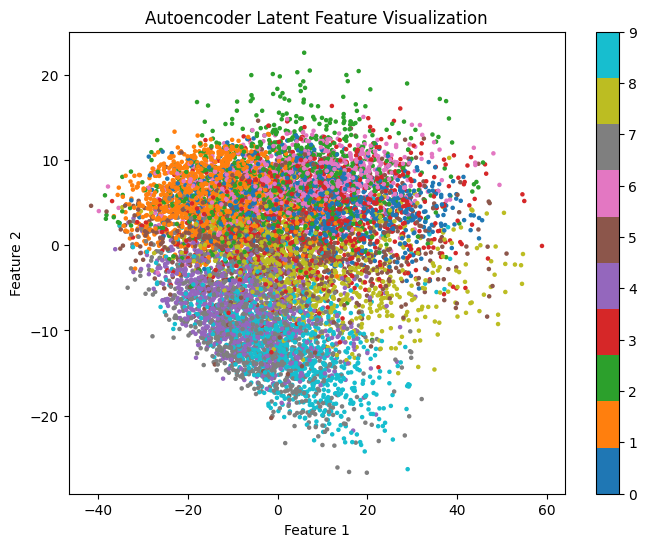

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


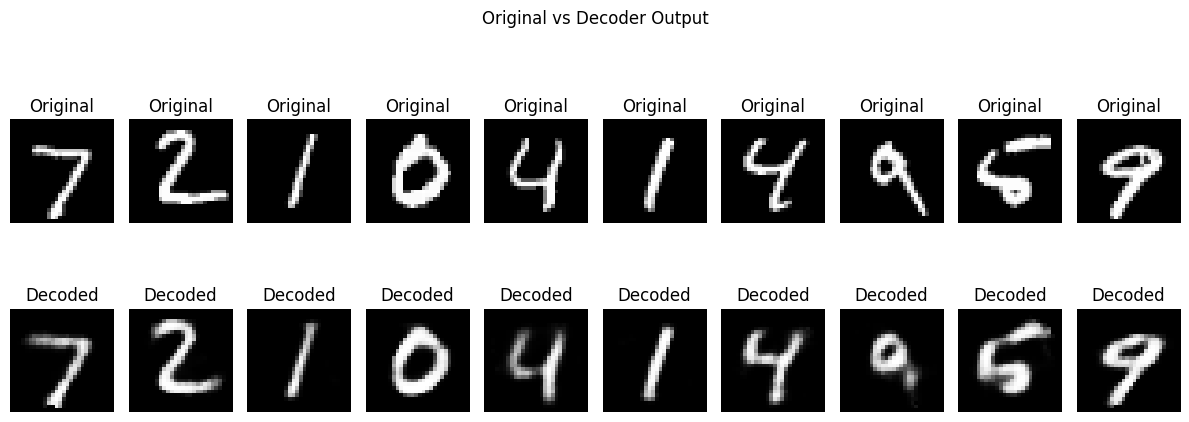


OBSERVATIONS
1. Original data contains 784 features.
2. Encoder compresses data into 32 features.
3. PCA visualizes the learned features in 2D.
4. Decoder reconstructs the original images.
5. Autoencoder performs dimensionality reduction successfully.

Experiment Completed Successfully!
Name: Lathika M
Roll No: 24BAD062


In [ ]:
# PART D: DIMENSIONALITY REDUCTION AND FEATURE VISUALIZATION

from sklearn.decomposition import PCA

# Student Details
print("Name: Lathika M")
print("Roll No: 24BAD062")

# Extract latent-space representations
latent_features = encoder.predict(x_test)

print("\nDIMENSIONALITY REDUCTION")
print("Original Data Shape:", x_test.shape)
print("Compressed Data Shape:", latent_features.shape)

# Apply PCA for 2D visualization
pca = PCA(n_components=2)
reduced_features = pca.fit_transform(latent_features)

# Visualize latent features
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    reduced_features[:, 0],
    reduced_features[:, 1],
    c=y_test,
    cmap='tab10',
    s=5
)

plt.colorbar(scatter)
plt.title("Autoencoder Latent Feature Visualization")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Reconstruct selected test samples using Decoder
selected_features = latent_features[:10]
decoded_images = decoder.predict(selected_features)

# Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(decoded_images[i].reshape(28, 28), cmap='gray')
    plt.title("Decoded")
    plt.axis('off')

plt.suptitle("Original vs Decoder Output")
plt.tight_layout()
plt.show()

print("\nOBSERVATIONS")
print("1. Original data contains 784 features.")
print("2. Encoder compresses data into 32 features.")
print("3. PCA visualizes the learned features in 2D.")
print("4. Decoder reconstructs the original images.")
print("5. Autoencoder performs dimensionality reduction successfully.")

print("\nExperiment Completed Successfully!")
print("Name: Lathika M")
print("Roll No: 24BAD062")